# 05. Klasteryzacja dobowych profili zapotrzebowania i cen (pytanie P5)

**Etap 4 projektu:** eksploracja danych metodami uczenia nienadzorowanego

Pytanie P5: jakie typowe profile dobowe zapotrzebowania i cen występują w KSE?

Każda doba opisana jest wektorem 24 wartości (godziny czasu lokalnego), a doby grupowane są
metodą k-średnich (K-means). Aby grupować doby według **kształtu** przebiegu, a nie według poziomu,
profile są normalizowane:

* zapotrzebowanie – dzielone przez średnią dobową (profil względny, średnia = 1),
* cena – standaryzowana w obrębie doby (odjęcie średniej i podzielenie przez odchylenie standardowe),
  ponieważ ceny mogą być ujemne, co wyklucza dzielenie przez średnią.

Kod klasteryzacji znajduje się w module `src/klasteryzacja.py`; wyniki zapisywane są w bazie
danych (tabele `klastry_*`) i prezentowane w aplikacji oraz w raporcie Power BI.

In [1]:
import sys
import warnings
from pathlib import Path

# ostrzeżenie biblioteki requests o wersjach zależności nie wpływa na wyniki
warnings.filterwarnings("ignore", message=".*doesn't match a supported version")

# katalog projektu (nadrzędny względem notebooks/) – dostęp do modułów src
sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import wykresy
from src.wykresy import format_polski

wykresy.ustaw_styl()

In [2]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

from src import baza_danych, klasteryzacja

zbior = baza_danych.wczytaj_zbior()

## 1. Profile dobowe zapotrzebowania

Funkcja `profile_dobowe()` tworzy tabelę doba × godzina. W dobach 23-godzinnych brakująca godzina
uzupełniana jest interpolacją, a w dobach 25-godzinnych powtórzona godzina jest uśredniana.

In [3]:
profile = klasteryzacja.profile_dobowe(zbior, "zapotrzebowanie_mw")
macierz = profile.div(profile.mean(axis=1), axis=0)
print(f"Macierz profili: {macierz.shape[0]} dób × {macierz.shape[1]} godzin")
macierz.head(3)

Macierz profili: 1734 dób × 24 godzin


godzina,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
data,,,,,,,,,,,,,,,,,,,,,,,,
2022-01-01,"0,96","0,93","0,90","0,87","0,86","0,86","0,86","0,86","0,87","0,91","0,95","1,01","1,04","1,07","1,08","1,09","1,14","1,15","1,15","1,15","1,13","1,09","1,06","0,99"
2022-01-02,"0,89","0,85","0,83","0,82","0,82","0,84","0,88","0,89","0,92","0,98","1,03","1,05","1,07","1,11","1,10","1,11","1,15","1,15","1,15","1,15","1,13","1,08","1,04","0,97"
2022-01-03,"0,73","0,71","0,70","0,70","0,72","0,77","0,92","1,02","1,08","1,12","1,12","1,14","1,15","1,16","1,14","1,15","1,17","1,17","1,15","1,14","1,12","1,04","0,97","0,91"


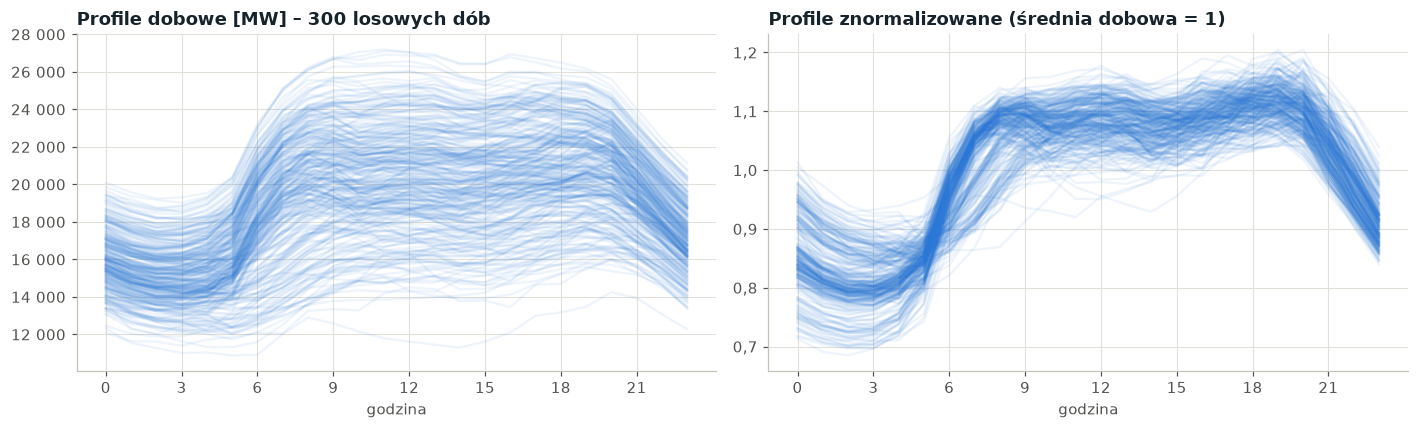

In [4]:
fig, osie = plt.subplots(1, 2, figsize=(13, 4))
probka = profile.sample(300, random_state=1)
for (_, wiersz) in probka.iterrows():
    osie[0].plot(range(24), wiersz.values, color=wykresy.NIEBIESKI, alpha=0.08)
    osie[1].plot(range(24), (wiersz / wiersz.mean()).values, color=wykresy.NIEBIESKI, alpha=0.08)
osie[0].set_title("Profile dobowe [MW] – 300 losowych dób")
osie[1].set_title("Profile znormalizowane (średnia dobowa = 1)")
for ax in osie:
    ax.set_xticks(range(0, 24, 3))
    ax.set_xlabel("godzina")
format_polski(osie[0])
format_polski(osie[1], miejsca=1)
plt.tight_layout()
plt.show()

Po normalizacji różnice poziomu (np. między zimą a latem) zostają usunięte, a widoczne pozostają różnice
kształtu – przede wszystkim między dniami roboczymi (wyraźny wzrost rano) a dniami wolnymi
(łagodniejszy przebieg).

## 2. Dobór liczby klastrów

Dla k = 2…8 obliczono sumę kwadratów odległości od środków klastrów (inercja, metoda łokcia)
oraz współczynnik sylwetki (miara rozdzielenia klastrów w zakresie −1…1).

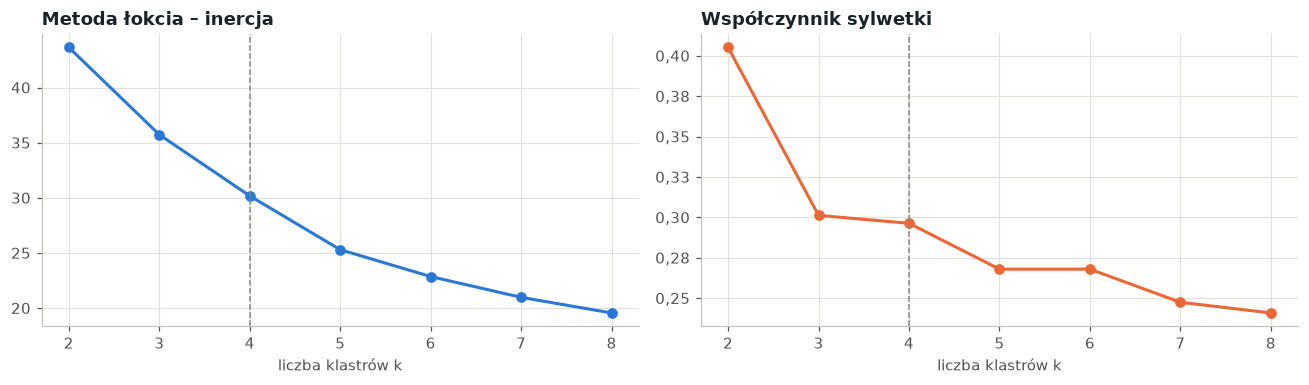

k,2,3,4,5,6,7,8
inercja,"43,64","35,73","30,17","25,29","22,85","20,97","19,55"
sylwetka,"0,41","0,30","0,30","0,27","0,27","0,25","0,24"


In [5]:
ocena = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(macierz.values)
    ocena.append({"k": k, "inercja": km.inertia_,
                  "sylwetka": silhouette_score(macierz.values, km.labels_, sample_size=1500, random_state=42)})
ocena = pd.DataFrame(ocena).set_index("k")

fig, osie = plt.subplots(1, 2, figsize=(12, 3.6))
osie[0].plot(ocena.index, ocena["inercja"], marker="o", color=wykresy.NIEBIESKI, linewidth=2)
osie[0].set_title("Metoda łokcia – inercja")
osie[1].plot(ocena.index, ocena["sylwetka"], marker="o", color=wykresy.POMARANCZOWY, linewidth=2)
osie[1].set_title("Współczynnik sylwetki")
for ax in osie:
    ax.axvline(4, color=wykresy.TUSZ_WYCISZONY, linestyle="--", linewidth=1)
    ax.set_xlabel("liczba klastrów k")
format_polski(osie[1], miejsca=2)
plt.tight_layout()
plt.show()
ocena.T

Współczynnik sylwetki jest najwyższy dla k = 2, jednak taki podział rozdziela wyłącznie dni robocze
i wolne, co jest znane z góry i nie wnosi nowej wiedzy. Przyjęto **k = 4**: sylwetka jest zbliżona
do wartości dla k = 3, a na wykresie inercji widoczne jest załamanie (łokieć) w okolicy k = 3–4.
Czwarty klaster pozwala dodatkowo oddzielić soboty od niedziel i świąt.

## 3. Klastry profili zapotrzebowania

Funkcja `klasteryzuj()` wykonuje klasteryzację i nadaje klastrom nazwy na podstawie udziału typów dni
i sezonów wśród dób należących do klastra.

In [6]:
doby, opis, srodki, _ = klasteryzacja.klasteryzuj(zbior, "zapotrzebowanie_mw", "srednia")
opis

,liczba_dob,sredni_poziom,udzial_dni_wolnych,nazwa
klaster,,,,
0,287,"15 689,13","0,99",niedziele i święta
1,936,"19 848,63","0,01",wtorki–piątki
2,250,"17 575,00","0,98",soboty
3,261,"19 320,02","0,00",poniedziałki


In [7]:
# zgodność przypisania dób z wynikami zapisanymi w bazie danych
zapisane = baza_danych.wczytaj("SELECT data, klaster FROM klastry_doby WHERE zmienna = 'zapotrzebowanie'")
porownanie = doby.merge(zapisane, on="data", suffixes=("", "_baza"))
zgodnosc = 100 * (porownanie["klaster"] == porownanie["klaster_baza"]).mean()
print(f"Doby przypisane identycznie jak w bazie danych: {zgodnosc:.1f}%".replace(".", ","))

Doby przypisane identycznie jak w bazie danych: 100,0%


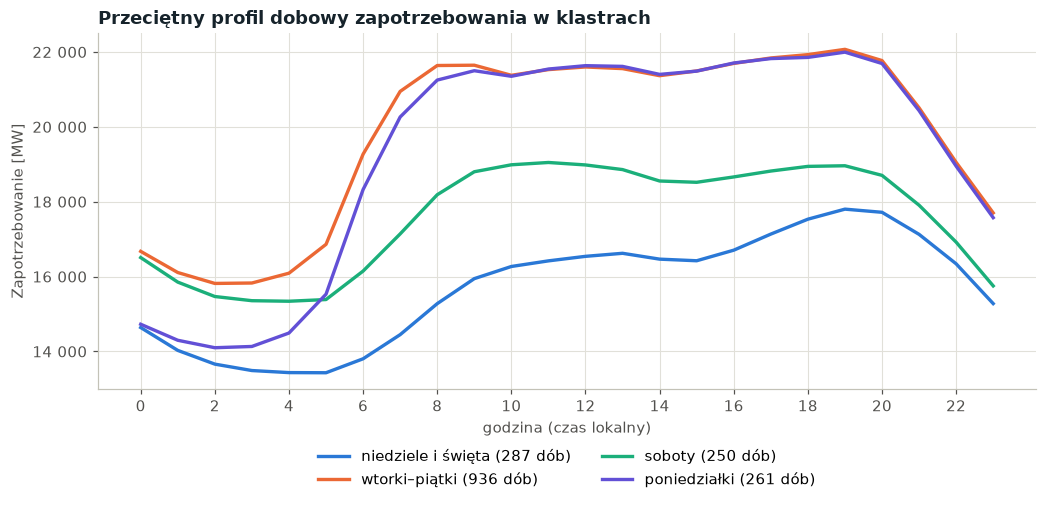

In [8]:
KOLORY_KLASTROW = [wykresy.NIEBIESKI, wykresy.POMARANCZOWY, wykresy.MORSKI, wykresy.FIOLET]

def rysuj_srodki(srodki, opis, tytul, jednostka):
    fig, ax = plt.subplots(figsize=(11, 4.2))
    for k, grupa in srodki.groupby("klaster"):
        ax.plot(grupa["godzina"], grupa["wartosc"], color=KOLORY_KLASTROW[k], linewidth=2.2,
                label=f"{opis.loc[k, 'nazwa']} ({opis.loc[k, 'liczba_dob']} dób)")
    ax.set_xticks(range(0, 24, 2))
    ax.set_xlabel("godzina (czas lokalny)")
    ax.set_ylabel(jednostka)
    ax.set_title(tytul)
    ax.legend(ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.13))
    format_polski(ax)
    plt.show()

rysuj_srodki(srodki, opis, "Przeciętny profil dobowy zapotrzebowania w klastrach", "Zapotrzebowanie [MW]")

In [9]:
# skład klastrów: udział dni tygodnia i typów dni [%]
nazwy = doby["nazwa_klastra"]
dni = pd.crosstab(nazwy, doby["dzien_tygodnia"].map(dict(enumerate(wykresy.DNI))), normalize="index") * 100
typy = pd.crosstab(nazwy, doby["typ_dnia"], normalize="index") * 100
display(dni[wykresy.DNI].round(1), typy.round(1))

dzien_tygodnia,pon,wt,śr,czw,pt,sob,nd
nazwa_klastra,,,,,,,
niedziele i święta,"4,20","2,10","1,70","3,10","1,70","3,80","83,30"
poniedziałki,"83,90","6,90","4,20","1,50","3,10","0,40","0,00"
soboty,"0,40","1,20","0,40","1,20","2,00","91,20","3,60"
wtorki–piątki,"1,70","23,60","24,70","24,70","24,50","0,90","0,00"


typ_dnia,pomostowy,roboczy,weekend,święto
nazwa_klastra,,,,
niedziele i święta,"1,00","0,00","81,50","17,40"
poniedziałki,"3,10","96,60","0,40","0,00"
soboty,"0,00","2,00","93,20","4,80"
wtorki–piątki,"0,60","98,50","0,90","0,00"


Klastry profili zapotrzebowania odpowiadają przede wszystkim typom dni (tabele powyżej): wtorki–piątki, poniedziałki,
soboty oraz niedziele i święta. Wynik ten nie był zakładany z góry – algorytm otrzymał wyłącznie
24 wartości dla każdej doby, bez informacji o kalendarzu. Wyodrębnienie poniedziałków wynika
z głębszego nocnego minimum po weekendzie (wolniejszy wzrost zapotrzebowania w nocy i rano). Doby
świąteczne przypadające w dni robocze (np. 1 i 3 maja, 15 sierpnia, okres świąteczno-noworoczny)
trafiają do klastra niedziel i świąt, co potwierdza zasadność zmiennej „święto” w modelu prognostycznym.

### 3.1. Wizualizacja klastrów w dwóch wymiarach (PCA)

Analiza składowych głównych (PCA) rzutuje 24-wymiarowe profile na dwie składowe wyjaśniające
największą część zmienności – pozwala to ocenić, na ile klastry są od siebie oddzielone.

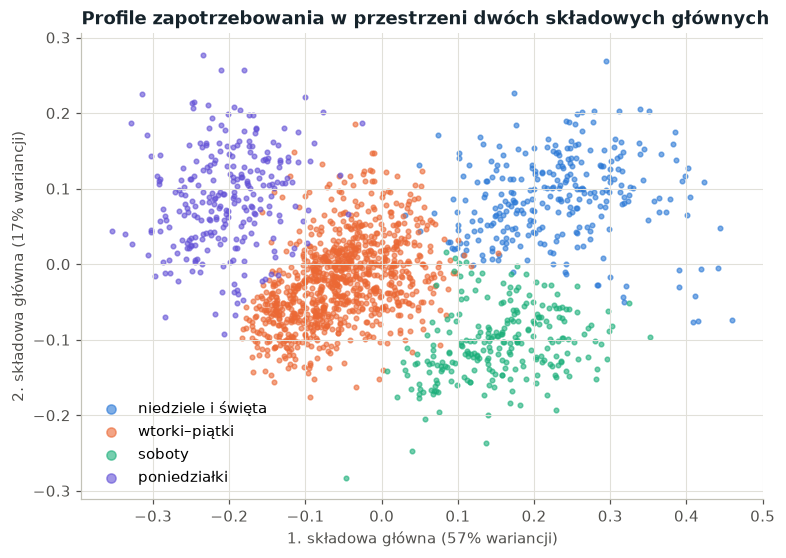

In [10]:
def wykres_pca(macierz, doby, opis, tytul):
    pca = PCA(n_components=2).fit(macierz.values)
    wspolrzedne = pca.transform(macierz.values)
    etykiety = doby.set_index("data").loc[macierz.index, "klaster"].values
    fig, ax = plt.subplots(figsize=(8, 5.5))
    for k in sorted(set(etykiety)):
        ax.scatter(wspolrzedne[etykiety == k, 0], wspolrzedne[etykiety == k, 1], s=9, alpha=0.6,
                   color=KOLORY_KLASTROW[k], label=opis.loc[k, "nazwa"])
    wyjasnione = pca.explained_variance_ratio_ * 100
    ax.set_xlabel(f"1. składowa główna ({wyjasnione[0]:.0f}% wariancji)")
    ax.set_ylabel(f"2. składowa główna ({wyjasnione[1]:.0f}% wariancji)")
    ax.set_title(tytul)
    ax.legend(loc="best", markerscale=2)
    plt.show()

wykres_pca(macierz, doby, opis, "Profile zapotrzebowania w przestrzeni dwóch składowych głównych")

## 4. Klastry profili cen energii

In [11]:
profile_cen = klasteryzacja.profile_dobowe(zbior, "cena_pln_mwh")
macierz_cen = profile_cen.sub(profile_cen.mean(axis=1), axis=0).div(profile_cen.std(axis=1) + 1e-9, axis=0)

doby_cen, opis_cen, srodki_cen, sylwetki_cen = klasteryzacja.klasteryzuj(zbior, "cena_pln_mwh", "standaryzacja")
display(sylwetki_cen.set_index("k").T, opis_cen)

k,2,3,4,5,6,7,8
sylwetka,"0,36","0,24","0,21","0,20","0,17","0,18","0,16"


,liczba_dob,sredni_poziom,udzial_dni_wolnych,nazwa
klaster,,,,
0,366,"533,66","0,25",dni robocze · zima–jesień
1,503,"430,91","0,49",dni robocze i wolne · wiosna–lato
2,437,"611,84","0,21",dni robocze · wiosna–lato
3,428,"566,14","0,25",dni robocze · zima


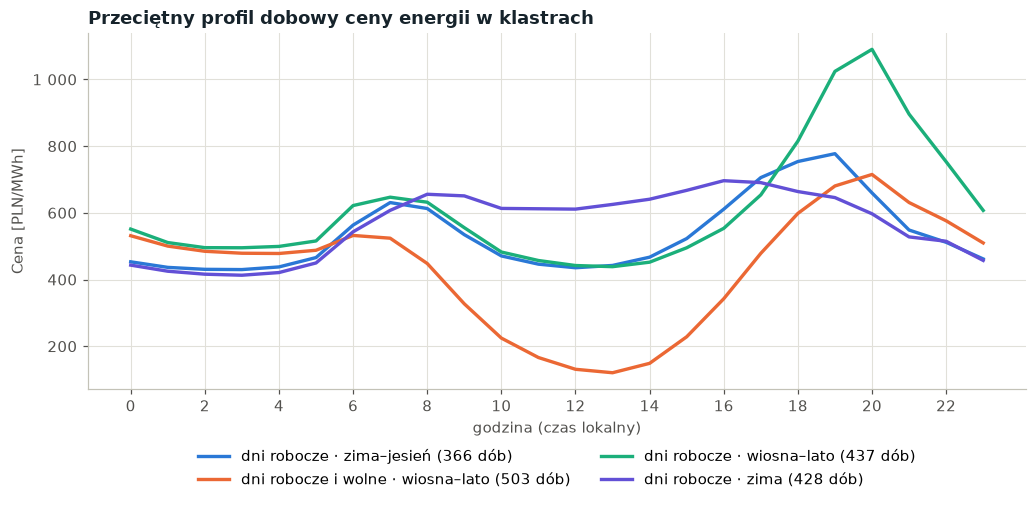

In [12]:
rysuj_srodki(srodki_cen, opis_cen, "Przeciętny profil dobowy ceny energii w klastrach", "Cena [PLN/MWh]")

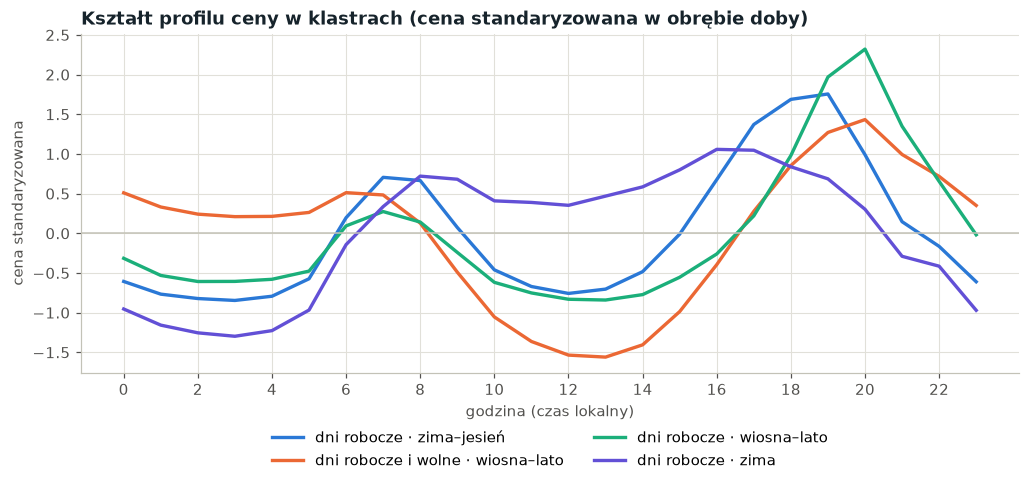

In [13]:
# profile znormalizowane – porównanie kształtu niezależnie od poziomu cen
fig, ax = plt.subplots(figsize=(11, 4))
for k, grupa in macierz_cen.groupby(doby_cen.set_index("data").loc[macierz_cen.index, "klaster"].values):
    ax.plot(range(24), grupa.mean().values, color=KOLORY_KLASTROW[k], linewidth=2.2, label=opis_cen.loc[k, "nazwa"])
ax.axhline(0, color=wykresy.OS, linewidth=1)
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("godzina (czas lokalny)")
ax.set_ylabel("cena standaryzowana")
ax.set_title("Kształt profilu ceny w klastrach (cena standaryzowana w obrębie doby)")
ax.legend(ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.13))
plt.show()

In [14]:
# rozmieszczenie klastrów w kalendarzu: każdy punkt to jedna doba
def kalendarz_klastrow(doby, opis, tytul):
    dni = pd.to_datetime(doby["data"])
    fig, ax = plt.subplots(figsize=(12, 3.6))
    for k in sorted(doby["klaster"].unique()):
        wybor = doby["klaster"] == k
        ax.scatter(dni[wybor].dt.dayofyear, dni[wybor].dt.year + (k - 1.5) * 0.12, s=6, marker="s",
                   color=KOLORY_KLASTROW[k], label=opis.loc[k, "nazwa"])
    ax.set_yticks(sorted(dni.dt.year.unique()))
    ax.set_xticks([pd.Timestamp(2023, m, 1).dayofyear for m in range(1, 13)], wykresy.MIESIACE)
    ax.set_title(tytul)
    ax.grid(axis="y", visible=False)
    ax.invert_yaxis()
    ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.1), markerscale=3)
    plt.show()

sezon,zima,wiosna,lato,jesień
nazwa_klastra,,,,
dni robocze i wolne · wiosna–lato,"1,80","43,50","41,40","13,30"
dni robocze · wiosna–lato,"1,80","33,40","50,60","14,20"
dni robocze · zima,"69,40","2,60","2,80","25,20"
dni robocze · zima–jesień,"29,00","23,00","5,20","42,90"


data,2022,2023,2024,2025,2026
nazwa_klastra,,,,,
dni robocze i wolne · wiosna–lato,58,60,88,131,166
dni robocze · wiosna–lato,124,102,93,74,44
dni robocze · zima,120,117,90,70,31
dni robocze · zima–jesień,63,86,95,90,32


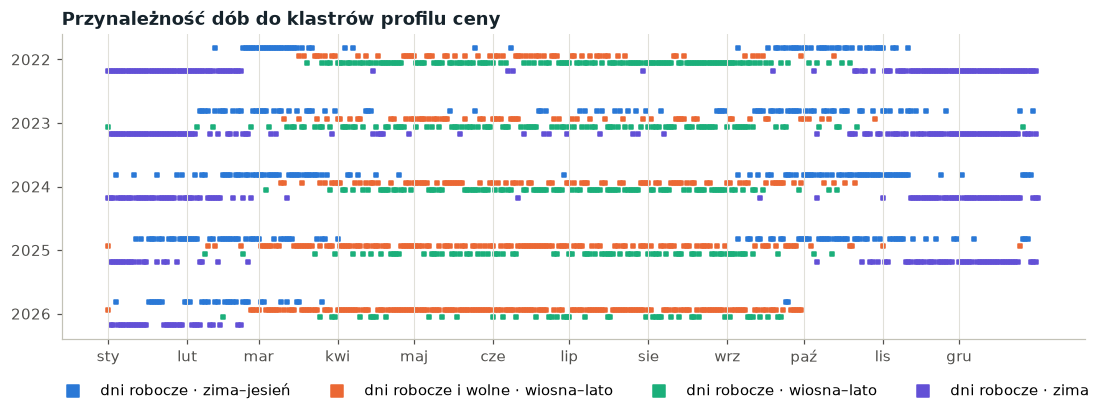

In [15]:
sezony = pd.crosstab(doby_cen["nazwa_klastra"], doby_cen["sezon"], normalize="index") * 100
lata = pd.crosstab(doby_cen["nazwa_klastra"], pd.to_datetime(doby_cen["data"]).dt.year)
display(sezony[["zima", "wiosna", "lato", "jesień"]].round(1), lata)
kalendarz_klastrow(doby_cen, opis_cen, "Przynależność dób do klastrów profilu ceny")

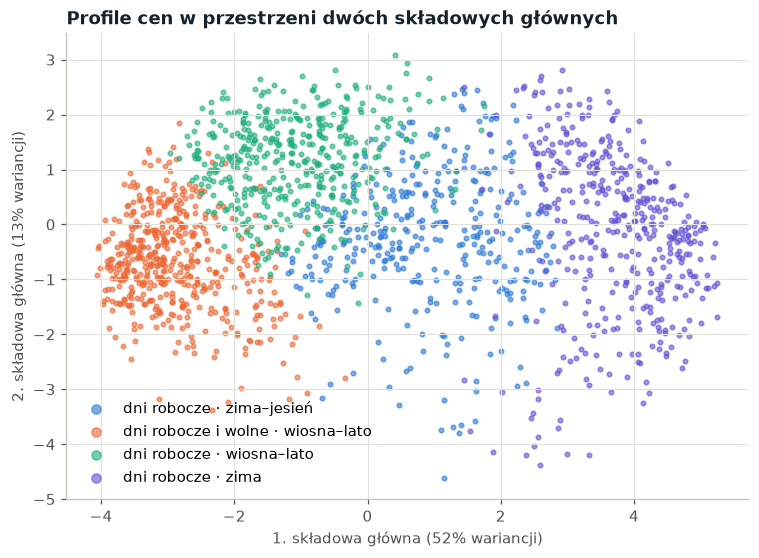

In [16]:
wykres_pca(macierz_cen, doby_cen, opis_cen, "Profile cen w przestrzeni dwóch składowych głównych")

Klastry profili cen różnią się położeniem i głębokością minimum w ciągu doby:

* **dni robocze · zima** – dwa szczyty (poranny ok. godz. 8 i popołudniowy ok. godz. 16–17), bez wyraźnego
  spadku w południe; klasyczny profil sprzed rozwoju fotowoltaiki,
* **dni robocze · zima–jesień** – szczyt poranny, umiarkowany spadek w południe i szczyt o godz. 18–19,
* **dni robocze · wiosna–lato** – niewielki szczyt poranny, spadek w południe i bardzo wyraźny szczyt
  wieczorny ok. godz. 20, po zachodzie słońca,
* **dni robocze i wolne · wiosna–lato** – głębokie minimum w godz. 11–14, często z cenami bliskimi zera
  lub ujemnymi; profil kształtowany przez generację PV (odpowiednik krzywej kaczki po stronie cen).

Liczba dób z profilem „południowego dołka” rośnie z roku na rok (58 dób w 2022 r., 131 w 2025 r.
i 166 w ciągu dziewięciu miesięcy 2026 r.), a liczba dób z klasycznym profilem zimowym maleje (120 w 2022 r.,
70 w 2025 r.). Struktura dobowa cen zmienia się więc wraz z przyrostem mocy w fotowoltaice.

## Podsumowanie

* **Profile zapotrzebowania** tworzą cztery wyraźnie oddzielone grupy (potwierdza to rzut PCA): wtorki–piątki
  (936 dób), poniedziałki (261), soboty (250) oraz niedziele i święta (287). Algorytm, nie znając
  kalendarza, odtworzył podział według typu dnia, co oznacza, że kształt dobowego przebiegu zapotrzebowania
  zależy przede wszystkim od organizacji pracy i życia codziennego, a w mniejszym stopniu od pory roku.
  Poniedziałki wyróżniają się głębszym nocnym minimum i wolniejszym porannym wzrostem zapotrzebowania.
* **Profile cen** grupują się przede wszystkim według pory roku: zimą dominuje profil z dwoma szczytami,
  a wiosną i latem – profil z minimum w południe i szczytem wieczornym. Udział dób z głębokim minimum
  południowym szybko rośnie w kolejnych latach.
* Wyniki mają znaczenie praktyczne: wskazują godziny, w których energia jest najtańsza (południe
  w sezonie wiosenno-letnim), co jest istotne dla odbiorców z taryfą dynamiczną, właścicieli magazynów
  energii i pojazdów elektrycznych, a także uzasadniają uwzględnienie w modelu prognostycznym zmiennych
  kalendarzowych (dzień tygodnia, święto, dzień pomostowy).
* Wyniki klasteryzacji zapisane w bazie danych (tabele `klastry_*`) są identyczne z uzyskanymi
  w notebooku.